# Data Observability & Lineage

A pipeline can succeed and still deliver wrong data: half the rows are missing, a column was renamed upstream, or
yesterday's file was loaded again. **Data observability** watches the data itself, not only the job status, with
five signals: **freshness, volume, schema, distribution and lineage**. **Lineage** records which job read which
datasets and wrote which ones, so that when something breaks you can see the cause upstream and the impact
downstream. **OpenLineage** is the open standard for lineage events; **Marquez** is its reference server.

**After this lesson you can:**

1. Emit OpenLineage run events (START, COMPLETE, FAIL) with dataset facets from a Python pipeline.
2. Query a lineage graph from Marquez and do upstream (root cause) and downstream (impact) analysis.
3. Build freshness, volume and schema monitors from run metadata, and detect real incidents.
4. Explain where lineage comes from in practice (Airflow, dbt, Spark, Flink integrations).

**Data:** NYC taxi trips, January 2024, processed one day per run for 21 days.
**Services:** PostgreSQL + Marquez: `docker compose -f docker/compose.yml --profile lineage up -d postgres marquez`
(API on http://localhost:5000).

In [1]:
import datetime as dt
import hashlib
import subprocess
import sys
import time
import uuid
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from openlineage.client import OpenLineageClient
from openlineage.client.event_v2 import InputDataset, Job, OutputDataset, Run, RunEvent, RunState
from openlineage.client.facet_v2 import (error_message_run, output_statistics_output_dataset, schema_dataset,
                                         sql_job)
from openlineage.client.transport.http import HttpConfig, HttpTransport

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("lineage", "postgres")
# Marquez stores its data in its own database (its default config expects user and password "marquez"):
# create both once in the course PostgreSQL
psql = ["docker", "compose", "-f", str(datasets.COMPOSE), "exec", "-T", "postgres", "psql", "-U", "course", "-d", "course", "-tAc"]
if subprocess.run(psql + ["SELECT 1 FROM pg_roles WHERE rolname = 'marquez'"], capture_output=True, text=True).stdout.strip() != "1":
    subprocess.run(psql + ["CREATE ROLE marquez LOGIN PASSWORD 'marquez'"], capture_output=True, text=True, check=True)
if subprocess.run(psql + ["SELECT 1 FROM pg_database WHERE datname = 'marquez'"], capture_output=True, text=True).stdout.strip() != "1":
    subprocess.run(psql + ["CREATE DATABASE marquez OWNER marquez"], capture_output=True, text=True, check=True)
subprocess.run(psql + ["ALTER DATABASE marquez OWNER TO marquez"], capture_output=True, text=True, check=True)
# each Marquez event is one transaction; on Docker Desktop disks a synchronous commit (fsync) takes seconds
subprocess.run(psql + ["ALTER ROLE marquez SET synchronous_commit = off"], check=True, capture_output=True)
datasets.ensure_service("lineage", "marquez")
MARQUEZ = "http://localhost:5000"
for _ in range(90):
    try:
        if requests.get("http://localhost:5001/healthcheck", timeout=2).ok:
            break
    except requests.RequestException:
        pass
    time.sleep(2)
NS = f"taxi-pipeline-{time.strftime('%H%M%S')}"     # a fresh namespace per notebook run
client = OpenLineageClient(transport=HttpTransport(HttpConfig(url=MARQUEZ, timeout=60)))
print("Marquez namespaces:", [n["name"] for n in requests.get(f"{MARQUEZ}/api/v1/namespaces", timeout=10).json()["namespaces"]][:5])
print("this run's job namespace:", NS)

Marquez namespaces: ['default', 'duckdb://warehouse', 'iceberg://lakehouse', 'iceberg://x', 'kafka://kafka:9092']
this run's job namespace: taxi-pipeline-213510


## 1. The Pipeline and Its Lineage Events

Three jobs run every morning for the previous day:

1. `ingest_trips`: the TLC export → `raw_trips`
2. `build_daily_zone_revenue`: `raw_trips` → `daily_zone_revenue`
3. `build_kpi_dashboard`: `daily_zone_revenue` + `zones` → `kpi_dashboard`

Each job emits a **START** event and then **COMPLETE** or **FAIL**. Events name the input and output datasets and
carry **facets**: the output schema, the row count, the SQL, and an error message on failure. Three incidents are
built into the input, like in real life:

| Day | Incident |
| :--- | :--- |
| 2024-01-12 | the upstream export is truncated: only half of the day arrives |
| 2024-01-16 | upstream renames `total_amount` to `total_usd` |
| 2024-01-18 | the export contains the previous day again (stale data) |

In [2]:
src = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID",
                                                         "trip_distance", "fare_amount", "total_amount"])
src = src[(src.tpep_pickup_datetime >= "2024-01-01") & (src.tpep_pickup_datetime < "2024-01-22")]
src["day"] = src.tpep_pickup_datetime.dt.date
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
wh = duckdb.connect()
wh.execute("SET enable_progress_bar = false")
wh.execute("CREATE TABLE raw_trips AS SELECT * EXCLUDE (day) FROM src LIMIT 0")
wh.execute("CREATE TABLE zones AS SELECT * FROM zones")
wh.execute("CREATE TABLE daily_zone_revenue (day DATE, borough TEXT, trips BIGINT, revenue DOUBLE)")
wh.execute("CREATE TABLE kpi_dashboard (day DATE, trips BIGINT, revenue DOUBLE, avg_fare DOUBLE)")

def upstream_export(day: dt.date) -> pd.DataFrame:
    """What the source system delivers for `day`, including the three incidents."""
    part = src[src.day == day].drop(columns="day")
    if day == dt.date(2024, 1, 12):
        part = part.iloc[: len(part) // 2]                               # truncated export
    if day == dt.date(2024, 1, 16):
        part = part.rename(columns={"total_amount": "total_usd"})       # upstream schema change
    if day == dt.date(2024, 1, 18):
        part = src[src.day == dt.date(2024, 1, 17)].drop(columns="day")  # stale: yesterday again
    return part

def ds_schema(df: pd.DataFrame) -> schema_dataset.SchemaDatasetFacet:
    return schema_dataset.SchemaDatasetFacet(fields=[schema_dataset.SchemaDatasetFacetFields(name=c, type=str(t))
                                                     for c, t in df.dtypes.items()])

def emit(state, job: str, run_id: str, when: dt.datetime, inputs=(), outputs=(), sql=None, error=None):
    job_facets = {"sql": sql_job.SQLJobFacet(query=sql)} if sql else {}
    run_facets = {"errorMessage": error_message_run.ErrorMessageRunFacet(message=error, programmingLanguage="python")} if error else {}
    client.emit(RunEvent(eventType=state, eventTime=when.isoformat(), run=Run(runId=run_id, facets=run_facets),
                         job=Job(namespace=NS, name=job, facets=job_facets), inputs=list(inputs), outputs=list(outputs),
                         producer="https://github.com/MuhammetAliVarlik/FromZeroToHero-DataScience-AI-Cloud"))

def out_ds(name: str, df: pd.DataFrame) -> OutputDataset:
    return OutputDataset(namespace="duckdb://warehouse", name=name, facets={"schema": ds_schema(df)},
                         outputFacets={"outputStatistics": output_statistics_output_dataset.OutputStatisticsOutputDatasetFacet(rowCount=len(df))})

def in_ds(name: str, namespace: str = "duckdb://warehouse") -> InputDataset:
    return InputDataset(namespace=namespace, name=name)

In [3]:
metrics = []                                          # what an observability tool collects from every run
SQL_DAILY = """SELECT CAST(tpep_pickup_datetime AS DATE) AS day, z.Borough AS borough, count(*) AS trips,
       sum(total_amount) AS revenue FROM batch b JOIN zones z ON z.LocationID = b.PULocationID GROUP BY 1, 2"""
SQL_KPI = "SELECT day, sum(trips), sum(revenue), sum(revenue) / sum(trips) FROM daily_zone_revenue WHERE day = ? GROUP BY day"

for day in sorted(src.day.unique()):
    run_at = dt.datetime.combine(day + dt.timedelta(days=1), dt.time(6, 0), tzinfo=dt.timezone.utc)
    export = upstream_export(day)

    # job 1: ingest
    rid = str(uuid.uuid4())
    emit(RunState.START, "ingest_trips", rid, run_at, inputs=[in_ds(f"yellow_tripdata_{day}.parquet", "s3://nyc-tlc")])
    known = [c for c, *_ in wh.execute("DESCRIBE raw_trips").fetchall()]
    batch = export.reindex(columns=known)           # a lenient loader: keeps known columns, missing ones become NULL
    wh.register("batch", batch)
    wh.execute("INSERT INTO raw_trips SELECT * FROM batch")
    emit(RunState.COMPLETE, "ingest_trips", rid, run_at + dt.timedelta(minutes=2),
         inputs=[in_ds(f"yellow_tripdata_{day}.parquet", "s3://nyc-tlc")], outputs=[out_ds("raw_trips", batch)])
    metrics.append({"day": day, "job": "ingest_trips", "state": "COMPLETE", "rows": len(batch),
                    "schema": hashlib.md5(",".join(export.columns).encode()).hexdigest()[:8], "columns": list(export.columns),
                    "max_event_time": batch.tpep_pickup_datetime.max(), "run_at": run_at})

    # job 2: daily revenue per borough
    rid = str(uuid.uuid4())
    t = run_at + dt.timedelta(minutes=3)
    emit(RunState.START, "build_daily_zone_revenue", rid, t, inputs=[in_ds("raw_trips"), in_ds("zones")], sql=SQL_DAILY)
    try:
        nulls = wh.execute("SELECT count(*) FROM batch WHERE total_amount IS NULL").fetchone()[0]
        if nulls:                                      # a data test, like dbt's not_null
            raise ValueError(f"data test not_null(total_amount) failed: {nulls:,} NULL values")
        daily = wh.execute(SQL_DAILY).df()
        wh.execute("INSERT INTO daily_zone_revenue SELECT * FROM daily")
        emit(RunState.COMPLETE, "build_daily_zone_revenue", rid, t + dt.timedelta(minutes=1),
             inputs=[in_ds("raw_trips"), in_ds("zones")], outputs=[out_ds("daily_zone_revenue", daily)], sql=SQL_DAILY)
        metrics.append({"day": day, "job": "build_daily_zone_revenue", "state": "COMPLETE", "rows": len(daily), "run_at": t})
    except (duckdb.Error, ValueError) as e:
        emit(RunState.FAIL, "build_daily_zone_revenue", rid, t + dt.timedelta(minutes=1),
             inputs=[in_ds("raw_trips"), in_ds("zones")], sql=SQL_DAILY, error=str(e).splitlines()[0])
        metrics.append({"day": day, "job": "build_daily_zone_revenue", "state": "FAIL", "rows": 0, "run_at": t,
                        "error": str(e).splitlines()[0]})
        continue                                       # the dashboard job is skipped for this day

    # job 3: dashboard KPIs
    rid = str(uuid.uuid4())
    t = run_at + dt.timedelta(minutes=5)
    emit(RunState.START, "build_kpi_dashboard", rid, t, inputs=[in_ds("daily_zone_revenue")], sql=SQL_KPI)
    kpi = wh.execute(SQL_KPI, [day]).df()
    kpi.columns = ["day", "trips", "revenue", "avg_fare"]
    wh.execute("INSERT INTO kpi_dashboard SELECT * FROM kpi")
    emit(RunState.COMPLETE, "build_kpi_dashboard", rid, t + dt.timedelta(minutes=1),
         inputs=[in_ds("daily_zone_revenue")], outputs=[out_ds("kpi_dashboard", kpi)], sql=SQL_KPI)
    metrics.append({"day": day, "job": "build_kpi_dashboard", "state": "COMPLETE", "rows": len(kpi), "run_at": t})

runs = pd.DataFrame(metrics)
print(runs.pivot_table(index="day", columns="job", values="state", aggfunc="first").fillna("skipped").to_string())
print()
print(runs[runs.state == "FAIL"][["day", "job", "error"]].to_string(index=False))

job        build_daily_zone_revenue build_kpi_dashboard ingest_trips
day                                                                 
2024-01-01                 COMPLETE            COMPLETE     COMPLETE
2024-01-02                 COMPLETE            COMPLETE     COMPLETE
2024-01-03                 COMPLETE            COMPLETE     COMPLETE
2024-01-04                 COMPLETE            COMPLETE     COMPLETE
2024-01-05                 COMPLETE            COMPLETE     COMPLETE
2024-01-06                 COMPLETE            COMPLETE     COMPLETE
2024-01-07                 COMPLETE            COMPLETE     COMPLETE
2024-01-08                 COMPLETE            COMPLETE     COMPLETE
2024-01-09                 COMPLETE            COMPLETE     COMPLETE
2024-01-10                 COMPLETE            COMPLETE     COMPLETE
2024-01-11                 COMPLETE            COMPLETE     COMPLETE
2024-01-12                 COMPLETE            COMPLETE     COMPLETE
2024-01-13                 COMPLET

Note what happened on 2024-01-16: `ingest_trips` **succeeded** (the lenient loader kept the known columns and filled
`total_amount` with NULL), and only the data test of the next job stopped the bad data. On 2024-01-12 and 2024-01-18 every job succeeded. Job status alone
would have caught one of the three incidents, and in the wrong place.

## 2. The Lineage Graph in Marquez

Marquez builds the graph from the events. `GET /api/v1/lineage?nodeId=...` returns the nodes (jobs and datasets)
connected to a dataset.

14 nodes, 21 edges
upstream of raw_trips (root-cause candidates, latest run's input): ['yellow_tripdata_2024-01-21.parquet']
downstream of raw_trips (impact if it is wrong): ['kpi_dashboard', 'daily_zone_revenue']


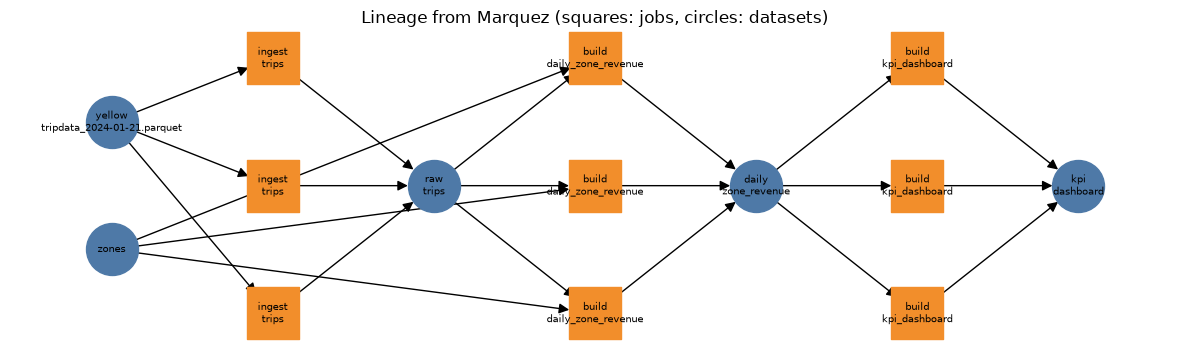

In [4]:
node = "dataset:duckdb://warehouse:raw_trips"
graph = requests.get(f"{MARQUEZ}/api/v1/lineage", params={"nodeId": node, "depth": 10}, timeout=30).json()["graph"]
G = nx.DiGraph()
for n in graph:
    for e in n["outEdges"]:
        G.add_edge(e["origin"], e["destination"])
label = {n: n.split(":")[-1] for n in G.nodes}
kind = {n: n.split(":")[0] for n in G.nodes}
print(f"{len(G.nodes)} nodes, {len(G.edges)} edges")
downstream = [label[n] for n in nx.descendants(G, node) if kind[n] == "dataset"]
upstream = [label[n] for n in nx.ancestors(G, node) if kind[n] == "dataset"]
print("upstream of raw_trips (root-cause candidates, latest run's input):", upstream)
print("downstream of raw_trips (impact if it is wrong):", downstream)

layers = {n: i for i, layer in enumerate(nx.topological_generations(G)) for n in layer}
nx.set_node_attributes(G, layers, "layer")
pos = nx.multipartite_layout(G, subset_key="layer")
plt.figure(figsize=(12, 3.6))
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if kind[n] == "job"], node_shape="s", node_color="#F28E2B", node_size=1400)
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if kind[n] == "dataset"], node_color="#4E79A7", node_size=1400)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=15, node_size=1400)
nx.draw_networkx_labels(G, pos, {n: label[n].replace("_", "\n", 1) for n in G}, font_size=7)
plt.title("Lineage from Marquez (squares: jobs, circles: datasets)"); plt.axis("off"); plt.tight_layout(); plt.show()

*Insight: Lineage answers the two questions of every data incident: "where did it come from?" (walk upstream) and "who is affected?" (walk downstream). Here a problem in `raw_trips` reaches the KPI dashboard through two jobs.*

## 3. Monitors: Freshness, Volume, Schema

The monitors use only metadata from the runs (row counts, schemas, the newest event time). They do not need to
scan the data.

- **Volume:** compare today's row count with the median of the last 7 runs; flag a deviation of more than 35 %.
  The median is robust: one bad day in the history does not move it, unlike the mean.
- **Schema:** flag any change of the column list.
- **Freshness:** at run time, the newest event should be less than 24 hours old.

       day   rows  vs_median_%  schema_alert  staleness_h  freshness_alert
2024-01-12  51827        -45.4         False          6.6            False
2024-01-16  93057         -1.4          True          6.0            False
2024-01-17 110365         16.9          True          6.0            False
2024-01-18 110365         16.9         False         30.0             True
schema change on 2024-01-16: removed ['total_amount'], added ['total_usd']
schema change on 2024-01-17: removed ['total_usd'], added ['total_amount']


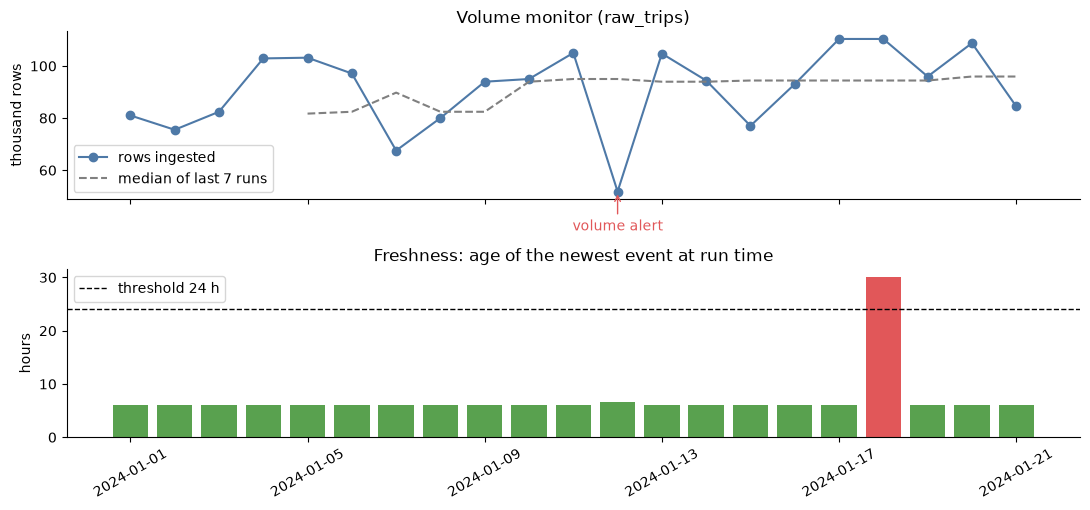

In [5]:
ing = runs[runs.job == "ingest_trips"].reset_index(drop=True)
med = ing.rows.rolling(7, min_periods=4).median().shift(1)
ing["vs_median_%"] = 100 * (ing.rows / med - 1)
ing["volume_alert"] = ing["vs_median_%"].abs() > 35
ing["schema_alert"] = ing.schema != ing.schema.shift(1)
ing.loc[0, "schema_alert"] = False
ing["staleness_h"] = (ing.run_at - ing.max_event_time.dt.tz_localize("UTC")).dt.total_seconds() / 3600
ing["freshness_alert"] = ing.staleness_h > 24
alerts = ing[ing.volume_alert | ing.schema_alert | ing.freshness_alert]
print(alerts[["day", "rows", "vs_median_%", "schema_alert", "staleness_h", "freshness_alert"]].round(1).to_string(index=False))
changed = ing[ing.schema_alert]
for _, r in changed.iterrows():
    before = ing.loc[_ - 1, "columns"]
    print(f"schema change on {r.day}: removed {sorted(set(before) - set(r.columns))}, added {sorted(set(r.columns) - set(before))}")

fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
ax[0].plot(ing.day, ing.rows / 1000, "o-", color="#4E79A7", label="rows ingested")
ax[0].plot(ing.day, med / 1000, "--", color="grey", label="median of last 7 runs")
for _, r in ing[ing.volume_alert].iterrows():
    ax[0].annotate("volume alert", (r.day, r.rows / 1000), xytext=(0, -28), textcoords="offset points", ha="center", color="#E15759",
                   arrowprops={"arrowstyle": "->", "color": "#E15759"})
ax[0].set(ylabel="thousand rows", title="Volume monitor (raw_trips)"); ax[0].legend(loc="lower left")
ax[1].bar(ing.day, ing.staleness_h, color=["#E15759" if a else "#59A14F" for a in ing.freshness_alert])
ax[1].axhline(24, color="black", ls="--", lw=1, label="threshold 24 h")
ax[1].set(ylabel="hours", title="Freshness: age of the newest event at run time"); ax[1].legend(loc="upper left")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

*Insight: Normal days also vary: Sunday 2024-01-07 is 25 % and Martin Luther King Day (2024-01-15) 18 % below the median. That is why the threshold is wide and relative to a recent median, not a fixed row count. Production tools (Elementary, Monte Carlo, Soda) model the weekly seasonality and can use tighter limits.*

All three incidents are now visible, at the dataset where they entered. Marquez also keeps the run history of every
job, which an on-call engineer checks first:

In [6]:
job_runs = requests.get(f"{MARQUEZ}/api/v1/namespaces/{NS}/jobs/build_daily_zone_revenue/runs", params={"limit": 50}, timeout=30).json()["runs"]
hist = pd.DataFrame([{"started": r["startedAt"][:10], "state": r["state"]} for r in job_runs]).sort_values("started")
print(hist.state.value_counts().to_string())
print("failed runs (start date; each run processes the previous day):", hist[hist.state == "FAILED"].started.tolist())
facets = requests.get(f"{MARQUEZ}/api/v1/namespaces/duckdb%3A%2F%2Fwarehouse/datasets/raw_trips", timeout=30).json()
print("raw_trips fields known to Marquez:", [f["name"] for f in facets["fields"]])

state
COMPLETED    20
FAILED        1
failed runs (start date; each run processes the previous day): ['2024-01-17']


raw_trips fields known to Marquez: ['tpep_pickup_datetime', 'PULocationID', 'DOLocationID', 'trip_distance', 'fare_amount', 'total_amount']


## 4. Where Lineage Comes From in Practice

Nobody writes these events by hand in production. Integrations emit them automatically:

| Tool | OpenLineage integration |
| :--- | :--- |
| Airflow (M11) | `apache-airflow-providers-openlineage`: operators report their inputs/outputs |
| dbt (M11) | `dbt-ol` wrapper: every model becomes a job with column-level lineage |
| Spark (M13) | `openlineage-spark` listener: reads the query plan |
| Flink (Lesson 03) | OpenLineage Flink listener for sources and sinks |

The receivers are Marquez, DataHub, OpenMetadata, Atlan, Collibra and cloud catalogs (Google Dataplex, Microsoft Purview).

## Real-World Use Case or Analogy

Lineage is like the **supply-chain records of a food company**: when one supplier delivers contaminated flour, the
records show which bakeries used that batch and which shops received their bread, so the recall is targeted.
Observability monitors are the **quality checks at the factory gate**: they weigh every delivery (volume), check the
label (schema) and the date (freshness) before the flour goes into the bread.

Data teams with hundreds of pipelines route these alerts to on-call channels, and use lineage to tell the owners of
affected dashboards before the business notices wrong numbers.